# Chapitre 7 - Cours 3 : mises à jour perdues, write skew et fantômes

Ce notebook couvre la fin de la section *Weak Isolation Levels* : *Preventing Lost
Updates* (*Atomic write operations*, *Explicit locking*, *Automatically detecting lost
updates*, *Compare-and-set*, *Conflict resolution and
replication*) et *Write Skew and Phantoms* (*Characterizing write skew*, *More examples of
write skew*, *Phantoms causing write skew*, *Materializing conflicts*). Le cours 2 a
traité ce que voit un **lecteur** ; ici, deux transactions **écrivent** en même temps.

**Plan.**

1. La mise à jour perdue : le cycle lire-modifier-écrire.
2. Opérations d'écriture atomiques.
3. Verrouillage explicite (`SELECT ... FOR UPDATE`) et interblocages.
4. Détection automatique des mises à jour perdues.
5. Écriture conditionnelle (*compare-and-set*).
6. Réplication : résolution des conflits.
7. Le write skew : les médecins de garde.
8. Autres exemples ; les fantômes.
9. Matérialiser les conflits.
10. Récapitulatif expérimental : quel niveau empêche quoi ?

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import sqlite3

from ddia import transactions as tr
from ddia.transactions import (R, W, S, INC, RFU, SFU, run, plot_history, plot_precedence,
                               precedence_graph, simulate_load, LEVEL_LABELS)
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. La mise à jour perdue (section *Preventing Lost Updates*)

Le scénario le plus courant de conflit entre écrivains : l'application **lit** une
valeur, la **modifie** dans son code, et la **réécrit**. Si deux transactions le font en
même temps, la seconde écriture n'inclut pas la modification de la première, qui est
perdue (« écrasée »). Exemples : incrémenter un compteur ou un solde, ajouter un élément
à une liste dans un document JSON, deux personnes qui éditent la même page de wiki et
renvoient chacune la page entière.

Mesurons l'ampleur du problème : 200 transactions incrémentent le même compteur, avec au
plus $c$ transactions actives en même temps (ordonnancement aléatoire, une opération par
transaction et par tic). Les transactions abandonnées sont réessayées.

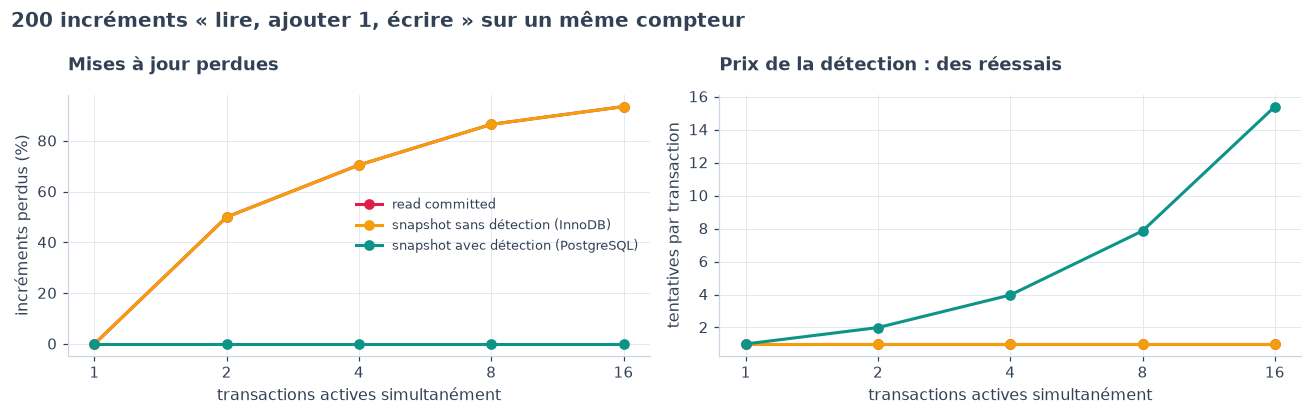

stratégie,read committed,snapshot avec détection (PostgreSQL),snapshot sans détection (InnoDB)
concurrence,,,
1,0,0,0
2,100,0,100
4,141,0,141
8,173,0,173
16,187,0,187


In [2]:
def incr_lu_ecrit(rng_, i):
    def prog():
        v = yield R("x")
        yield W("x", v + 1)
    return prog


conc = [1, 2, 4, 8, 16]
cas = {"read committed": dict(level="read_committed"),
       "snapshot sans détection (InnoDB)": dict(level="snapshot", detect_lost_updates=False),
       "snapshot avec détection (PostgreSQL)": dict(level="snapshot")}
lignes = []
for nom, kw in cas.items():
    for c in conc:
        out = simulate_load(incr_lu_ecrit, 200, concurrency=c, seed=1, initial={"x": 0}, **kw)
        lignes.append(dict(stratégie=nom, concurrence=c, perdues=200 - out["final"]["x"],
                           tentatives_par_tx=out["tentatives"] / 200))
perte = pd.DataFrame(lignes)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for (nom, g), c in zip(perte.groupby("stratégie", sort=False), [ROSE, AMBER, TEAL]):
    axes[0].plot(g["concurrence"], g["perdues"] / 2, marker="o", color=c, label=nom)
    axes[1].plot(g["concurrence"], g["tentatives_par_tx"], marker="o", color=c, label=nom)
axes[0].set_ylabel("incréments perdus (%)")
axes[0].set_title("Mises à jour perdues")
axes[1].set_ylabel("tentatives par transaction")
axes[1].set_title("Prix de la détection : des réessais")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(conc); ax.set_xticklabels(conc)
    ax.set_xlabel("transactions actives simultanément")
axes[0].legend(fontsize=8.5)
finish(fig, "200 incréments « lire, ajouter 1, écrire » sur un même compteur")
plt.show()
perte.pivot(index="concurrence", columns="stratégie", values="perdues")

Dès deux transactions concurrentes, *read committed* et une snapshot isolation sans
détection perdent une fraction notable des incréments (leurs courbes se superposent :
dans ce scénario, chaque transaction lit au début et écrit juste après, si bien que
l'instantané et la dernière valeur validée coïncident), et la perte croît avec la
concurrence (à 16, l'immense majorité des incréments disparaît). La snapshot isolation
de PostgreSQL ne perd rien, mais au prix de nombreux réessais. Les sections suivantes
passent en revue les remèdes.

> **À retenir.** Lire, modifier dans l'application, puis réécrire n'est pas sûr sous les
> niveaux faibles : la perte est silencieuse et croît avec la concurrence.

## 2. Opérations d'écriture atomiques (section *Atomic write operations*)

Le meilleur remède, quand il s'applique : laisser la **base** faire la modification, en
une seule instruction, par exemple `UPDATE compteurs SET valeur = valeur + 1 WHERE cle =
'foo'`. MongoDB offre des modifications atomiques de parties d'un document, Redis des
opérations atomiques sur ses structures. L'implémentation prend un verrou exclusif sur
l'objet pendant la lecture-modification (ou exécute toutes ces opérations sur un seul
fil). L'opération `INC` du moteur fait exactement cela.

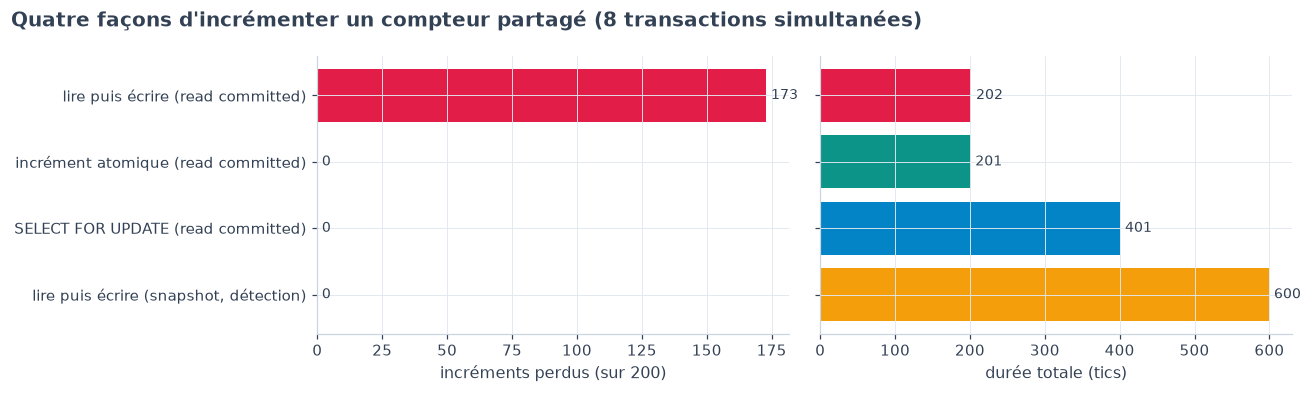

,incréments_perdus,tentatives,tics,attentes
stratégie,,,,
lire puis écrire (read committed),173,200,202,1073
incrément atomique (read committed),0,200,201,1282
SELECT FOR UPDATE (read committed),0,200,401,1372
"lire puis écrire (snapshot, détection)",0,1572,600,1372


In [3]:
def incr_atomique(rng_, i):
    def prog():
        yield INC("x")
    return prog


def incr_for_update(rng_, i):
    def prog():
        v = yield RFU("x")
        yield W("x", v + 1)
    return prog


strategies = {
    "lire puis écrire (read committed)": (incr_lu_ecrit, dict(level="read_committed")),
    "incrément atomique (read committed)": (incr_atomique, dict(level="read_committed")),
    "SELECT FOR UPDATE (read committed)": (incr_for_update, dict(level="read_committed")),
    "lire puis écrire (snapshot, détection)": (incr_lu_ecrit, dict(level="snapshot")),
}
res_strat = []
for nom, (prog, kw) in strategies.items():
    out = simulate_load(prog, 200, concurrency=8, seed=2, initial={"x": 0}, **kw)
    res_strat.append(dict(stratégie=nom, incréments_perdus=200 - out["final"]["x"],
                          tentatives=out["tentatives"], tics=out["tics"], attentes=out["attentes"]))
res_strat = pd.DataFrame(res_strat).set_index("stratégie")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
cols = [ROSE, TEAL, SKY, AMBER]
axes[0].barh(res_strat.index, res_strat["incréments_perdus"], color=cols)
axes[0].set_xlabel("incréments perdus (sur 200)")
axes[1].barh(res_strat.index, res_strat["tics"], color=cols)
axes[1].set_xlabel("durée totale (tics)")
axes[1].set_yticklabels([])
for ax in axes:
    ax.invert_yaxis()
    annotate_bars(ax, "{:.0f}")
finish(fig, "Quatre façons d'incrémenter un compteur partagé (8 transactions simultanées)")
plt.show()
res_strat

L'incrément atomique ne perd rien, ne provoque aucun abandon et finit le plus vite : la
lecture et l'écriture tiennent en une opération, le verrou est tenu brièvement. Le
`SELECT FOR UPDATE` est correct aussi mais fait **attendre** les autres transactions
pendant tout le cycle lire-modifier-écrire. La snapshot isolation avec détection est
correcte mais gaspille des tentatives. Le livre met en garde contre les ORM, qui
génèrent facilement des cycles lire-modifier-écrire dangereux au lieu des opérations
atomiques de la base.

> **À retenir.** Si la modification s'exprime comme une opération de la base (incrément,
> ajout à une liste...), c'est le remède le plus simple et le plus rapide.